In [18]:
!pip install tensorflow
!pip install keras-ocr
!pip install easyocr
!pip install "paddleocr>=2.0.1"

ERROR: Error checking for conflicts.
Traceback (most recent call last):
  File "/home/blukash/.pyenv/versions/3.7.11/lib/python3.7/site-packages/pip/_vendor/pkg_resources/__init__.py", line 3021, in _dep_map
    return self.__dep_map
  File "/home/blukash/.pyenv/versions/3.7.11/lib/python3.7/site-packages/pip/_vendor/pkg_resources/__init__.py", line 2815, in __getattr__
    raise AttributeError(attr)
AttributeError: _DistInfoDistribution__dep_map

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/blukash/.pyenv/versions/3.7.11/lib/python3.7/site-packages/pip/_vendor/pkg_resources/__init__.py", line 3012, in _parsed_pkg_info
    return self._pkg_info
  File "/home/blukash/.pyenv/versions/3.7.11/lib/python3.7/site-packages/pip/_vendor/pkg_resources/__init__.py", line 2815, in __getattr__
    raise AttributeError(attr)
AttributeError: _pkg_info

During handling of the above exception, another exception occurred:

Tracebac

In [4]:
!pip install tensorboard

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 16.0 MB/s eta 0:00:0000:0100:01
  Using cached tensorboard_data_server-0.7.0-py3-none-manylinux2014_x86_64.whl (6.6 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 304.5/304.5 kB 6.3 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 19.8 MB/s eta 0:00:0000:0100:01
  Using cached absl_py-1.4.0-py3-none-any.whl (126 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 181.3/181.3 kB 6.0 MB/s eta 0:00:00
  Using cached requests_oauthlib-1.3.1-py2.py3-none-any.whl (23 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.7/151.7 kB 3.4 MB/s eta 0:00:00a 0:00:01


In [5]:

%load_ext tensorboard

In [1]:
import keras_ocr
import matplotlib.pyplot as plt

2022-10-19 16:08:09.961359: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-10-19 16:08:10.149734: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/blukash/.pyenv/versions/3.7.11/lib/python3.7/site-packages/cv2/../../lib64:
2022-10-19 16:08:10.149766: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2022-10-19 16:08:10.194686: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when 

In [3]:
pipeline = keras_ocr.pipeline.Pipeline()

Looking for /home/blukash/.keras-ocr/craft_mlt_25k.h5
Looking for /home/blukash/.keras-ocr/crnn_kurapan.h5


In [15]:
images = [
    keras_ocr.tools.read(img) for img in [
        # './datasets/ruler_digit/images/all/DSC_0090.JPG',
        './datasets/ruler_digit/images/all/DSC_0631.JPG',
        ]
]

In [16]:
prediction_groups = pipeline.recognize(images)

2022-10-19 18:20:40.729940: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 603979776 exceeds 10% of free system memory.


1/1 [==============================] - 1s 771ms/step


In [6]:
prediction_groups[0][0]

('4',
 array([[1576.25  , 1912.7188],
        [1609.5938, 1912.7188],
        [1609.5938, 1952.125 ],
        [1576.25  , 1952.125 ]], dtype=float32))

<AxesSubplot:>

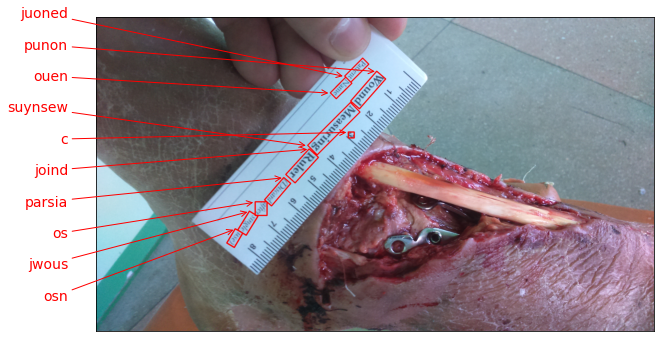

In [17]:
fig, axs = plt.subplots(nrows=len(images), figsize=(10, 20))
keras_ocr.tools.drawAnnotations(image=images[0], 
                                predictions=prediction_groups[0],
                                ax=axs)